# Seismic Analysis of the 2026 Flores Earthquake: Waveform, Spectral and Aftershock Characteristics

## Event Overview

On 14 August 2026 at 21:58 UTC (15 August 2026 05:58 local time), a major
Mw 7.7 earthquake occurred in the Flores Sea, eastern Indonesia.
The earthquake was shallow, with the epicentre located offshore north of
Flores Island, East Nusa Tenggara. The event was associated with
thrust faulting along the Flores Back-Arc Thrust system.

The earthquake generated a significant aftershock sequence, including
several events with magnitudes greater than 5.0. Meteorological, Climatological, and Geophysical Agency (BMKG) reported more than
1,600 aftershocks within the first few days, with the sequence
continuing to evolve during the following weeks.

## Impact

The earthquake produced strong ground shaking across Flores and
surrounding regions and generated a tsunami. Tsunami observations
reported maximum wave heights of approximately 1.6 m at locations
including Reo and Pota.

The earthquake caused substantial human and infrastructure impacts.
As post-event assessments progressed, reported casualties and damage
increased. A provisional assessment reported 135 deaths, 1,764
injuries and more than 60,000 displaced people, with tens of thousands
of buildings reported damaged.

The earthquake also triggered landslides and affected roads,
health facilities, schools and other public infrastructure, complicating
rescue and relief operations.

## Seismic Analysis

This notebook investigates the seismic characteristics of the
2026 Flores earthquake and its associated sequence using waveform and
earthquake-catalogue data. The analysis includes:

- Waveform and spectrogram analysis
- Earthquake catalogue analysis:
  Magnitude–time distribution,
  Foreshock and aftershock activity

The waveform data are obtained from the EarthScope FDSN services,
while earthquake catalogue information is obtained from the
International Seismological Centre (ISC).

### For more details on the event

[2026 Flores earthquake — Wikipedia](https://en.wikipedia.org/wiki/2026_Flores_earthquake)

In [110]:
# Install ObsPy (run this cell only once if ObsPy is not already installed)
#!pip install obspy

In [111]:
# Import libraries for plotting and date/time handling
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Import ObsPy utilities for working with seismic data and UTC time
from obspy import UTCDateTime
from obspy.clients.fdsn import Client

# Connect to the EarthScope FDSN web services
client = Client("EARTHSCOPE")

In [112]:
# Define station and waveform parameters
network = "IU"       # Seismic network code for Global Seismographic Network
station = "TATO"     # Station code (Taipai, Taiwan)
location = "00"      # Location code
channel = "BHZ"      # Broadband vertical-component channel

# Define the time window for waveform retrieval (UTC)
startt = UTCDateTime("2026-08-14T21:55:00")    # A few seconds before the earthquake
endt = UTCDateTime("2026-08-14T22:55:00")      # Note: endt = startt + 1 hour

# Download the BHZ waveform from EarthScope FDSN services
st = client.get_waveforms(
    network, station, location, channel, startt, endt
)

In [113]:
# Display a summary of the retrieved seismic waveform
print(st)

1 Trace(s) in Stream:
IU.TATO.00.BHZ | 2026-08-14T21:55:00.019538Z - 2026-08-14T22:54:59.994538Z | 40.0 Hz, 144000 samples


The output shows that the downloaded `Stream` contains **one trace**:

In [114]:
# Extract the first (and only) trace from the stream
tr = st[0]

In [115]:
# Display metadata for the trace in the stream
print(tr.stats)

               network: IU
               station: TATO
              location: 00
               channel: BHZ
             starttime: 2026-08-14T21:55:00.019538Z
               endtime: 2026-08-14T22:54:59.994538Z
         sampling_rate: 40.0
                 delta: 0.025
                  npts: 144000
                 calib: 1.0
_fdsnws_dataselect_url: https://service.earthscope.org/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'D', 'number_of_records': 560, 'encoding': 'STEIM2', 'byteorder': '>', 'record_length': 512, 'filesize': 286720})
            processing: ['ObsPy 1.5.1: trim(endtime=UTCDateTime(2026, 8, 14, 22, 54, 59, 994538)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2026, 8, 14, 21, 54, 59, 994538))']


## Trace Statistics

The waveform contains 144,000 samples recorded over approximately 1 hour
at a sampling frequency of 40 Hz.

Therefore, the Nyquist frequency is:

$$
f_N = \frac{f_s}{2} = \frac{40}{2} = 20\ \mathrm{Hz}
$$

Thus, the recorded signal can represent frequencies up to 20 Hz.

The `BHZ` channel represents the vertical component of the broadband
seismic recording at station TATO, Taiwan. The waveform covers the period
from 21:55 to 22:55 UTC on 14 August 2026, providing a one-hour window for
analysis of the earthquake signal and its frequency content.

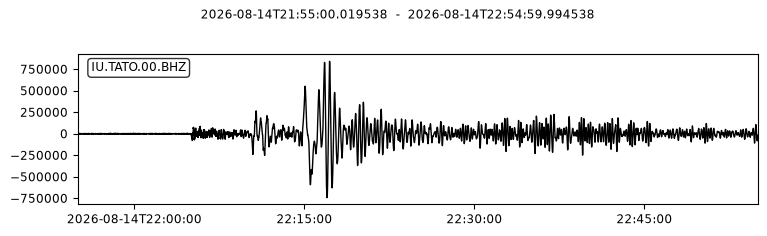

In [116]:
# Plot the raw seismic waveform
fig = tr.plot()

## Observations
From the above figure, we observe that the earthquake is clearly recorded at
station TATO, with the first P-wave arrival occurring at approximately
22:05 UTC.

The earthquake origin time is 21:58:21 UTC, giving an approximate P-wave
travel time of:

$$
\Delta t = 22{:}05{:}00 - 21{:}58{:}21 = 399\ \mathrm{s}
$$

The source–station distance is approximately 3,704 km (on great circle).

The apparent P-wave velocity can therefore be estimated as:

$$
V_P = \frac{D}{\Delta t}
$$

$$
V_P = \frac{3704}{399}
\approx 9.3\ \mathrm{km/s}
$$

Thus, the estimated apparent P-wave velocity along the
source–station path is approximately **9.3 km/s**.

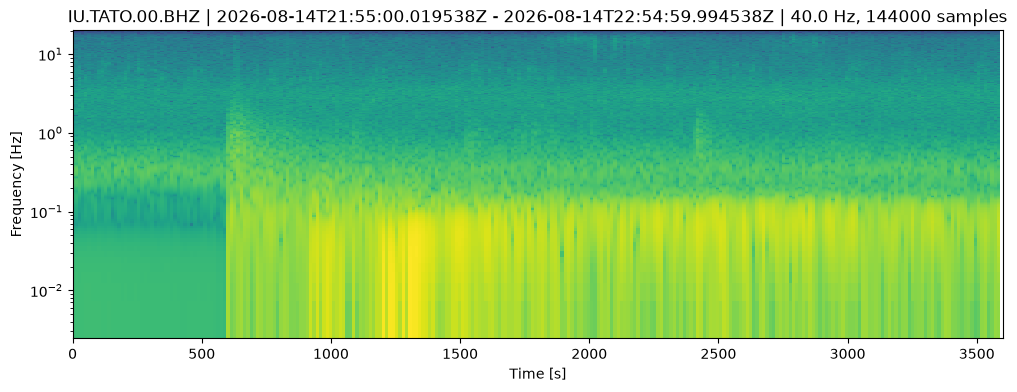

In [117]:
# Generate a spectrogram to examine the time-frequency characteristics
# of the seismic waveform
plt.rcParams['figure.figsize'] = (12, 4)
tr.spectrogram(per_lap=0.5, wlen=20, log=True, dbscale=True)    # 50% overlap and 20s window length

## Spectrogram Observations

The spectrogram shows a clear change in the frequency content of the seismic
signal after approximately 600 s, corresponding to about 22:05 UTC,
consistent with the estimated P-wave arrival.

Following the arrival, the seismic energy becomes stronger across a broad
frequency range, with most of the sustained energy concentrated at frequencies
below approximately 1 Hz.

The strongest spectral energy occurs later in the record, while the signal
gradually becomes weaker with time. The earthquake therefore produces a
distinct, long-duration time–frequency signature at station TATO.

The spectrogram also shows that the earthquake signal is dominated by
low-frequency energy, which is expected for a large, distant earthquake
recorded at teleseismic distance.

# Earthquake Catalogue for Foreshock and Aftershock Study

We have examined the raw waveform and spectrogram recorded at station
TATO, identifying the earthquake arrival and its time–frequency characteristics.
We now examine the earthquake catalogue to investigate the foreshock and
aftershock activity associated with the 14 August 2026 mainshock.

The preliminary USGS finite-fault rupture model indicates a primary
rupture dimension of approximately 150 × 40 km, with a rupture duration
of about 51 s.

Accordingly, a 1.5° search radius, corresponding to approximately
167 km, is selected around the reference location
(8.336°S, 121.345°E). This radius is sufficiently large to encompass the
estimated rupture extent while also providing spatial coverage of the
surrounding foreshock and aftershock activity.

The earthquake catalogue is retrieved from the International Seismological
Centre (ISC) for the period from 14 July to 14 September 2026, with a
minimum magnitude of M2.0.

In [118]:
# Define the catalogue time window
startt = UTCDateTime("2026-07-14T21:50:00")
endt = UTCDateTime("2026-09-14T21:50:00")

# Define the search region and minimum magnitude
maxrad = 1.5       # Search radius in degrees
lat = -8.336       # Reference latitude
lon = 121.345      # Reference longitude
minmag = 2.0       # Minimum earthquake magnitude

# Connect to the ISC earthquake catalogue
client = Client("ISC")

# Retrieve earthquakes within the specified time, region, and magnitude range
cat = client.get_events(
    starttime=startt,
    endtime=endt,
    latitude=lat,
    longitude=lon,
    maxradius=maxrad,
    minmagnitude=minmag
)

In [119]:
# Display the catalogue summary
print(cat)

740 Event(s) in Catalog:
2026-07-18T10:12:24.590000Z |  -8.274, +120.497 | 3.4  mb
2026-08-02T14:17:41.180000Z |  -8.351, +121.295 | 3.9  mb
...
2026-09-14T14:10:58.350000Z |  -8.106, +121.145 | 3.8  mb
2026-09-14T20:16:54.690000Z |  -8.793, +120.954 | 3.5  mb
To see all events call 'print(CatalogObject.__str__(print_all=True))'


Note: We have 740 events.

In [120]:
# Extract origin times and magnitudes from the catalogue
times = []
mags = []

for event in cat:
    times.append(event.origins[0].time.datetime)
    mags.append(event.magnitudes[0].mag)

# Convert times to Matplotlib date format for plotting
mtimes = mdates.date2num(times)

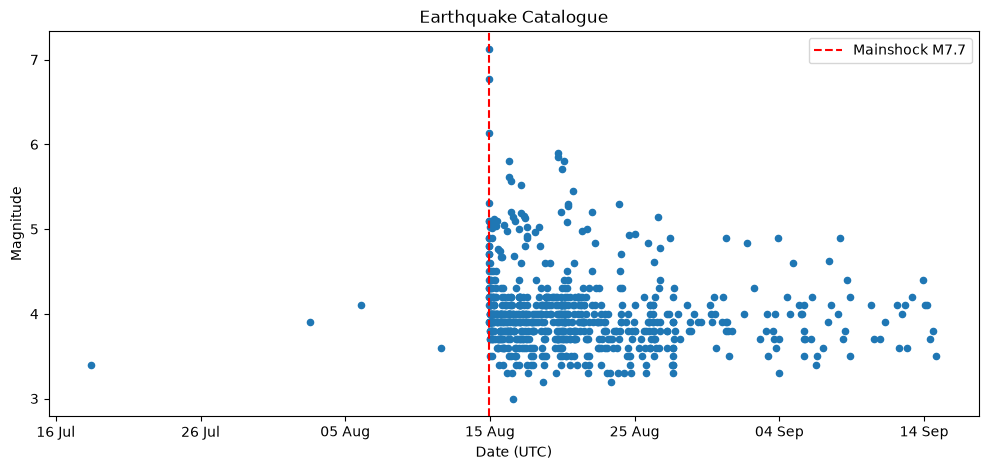

In [122]:
# Plot earthquake magnitude versus origin time
plt.figure(figsize=(12, 5))
plt.scatter(mtimes, mags, s=20)

# Mark the mainshock
plt.axvline(
    mdates.date2num(UTCDateTime("2026-08-14T21:58:23").datetime),
    ls="--", color="r", label="Mainshock M7.7"
)

# Format the time axis
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plt.xlabel("Date (UTC)")
plt.ylabel("Magnitude")
plt.title("Earthquake Catalogue")
plt.legend()
plt.show()

## Interpretation

The magnitude–time distribution shows a pronounced increase in seismic
activity immediately following the 14 August 2026 M7.7 mainshock.

Before the mainshock, only a small number of earthquakes are observed within
the selected spatial and temporal window. Following the mainshock, the
catalogue becomes densely populated with events, including several
moderate-to-large aftershocks.

The aftershock activity is strongest immediately after the mainshock and
gradually decreases with time, while earthquakes continue to occur throughout
the observation period.

## Discussion

The temporal pattern is characteristic of a mainshock–aftershock sequence.
The concentration of earthquakes following the mainshock indicates a strong
triggering response in the surrounding crust.

The magnitude of the aftershocks generally decreases with time, although
several relatively large events occur during the early part of the sequence.
The sparse seismicity before the mainshock suggests limited foreshock
activity within the selected catalogue, although the identification of
foreshocks depends on catalogue completeness and the chosen magnitude
threshold.

## Result

The earthquake catalogue clearly captures the temporal evolution of the
14 August 2026 earthquake sequence, with a dominant M7.7 mainshock
followed by intense aftershock activity.

The observed concentration of events immediately after the mainshock and
their subsequent decrease with time provide clear evidence of an
aftershock sequence within the selected 1.5° search region.

## Acknowledgements

This analysis uses seismic waveform data obtained through the EarthScope FDSN
services and earthquake catalogue data from the International Seismological
Centre (ISC). We acknowledge these organizations for providing open access
to seismic data and associated services.

We also acknowledge the United States Geological Survey (USGS) for the
finite-fault rupture information used to assess the spatial extent of the
earthquake sequence.